Hola **Laura**!

Soy **Patricio Requena** 👋. Es un placer ser el revisor de tu proyecto el día de hoy!

Revisaré tu proyecto detenidamente con el objetivo de ayudarte a mejorar y perfeccionar tus habilidades. Durante mi revisión, identificaré áreas donde puedas hacer mejoras en tu código, señalando específicamente qué y cómo podrías ajustar para optimizar el rendimiento y la claridad de tu proyecto. Además, es importante para mí destacar los aspectos que has manejado excepcionalmente bien. Reconocer tus fortalezas te ayudará a entender qué técnicas y métodos están funcionando a tu favor y cómo puedes aplicarlos en futuras tareas. 

_**Recuerda que al final de este notebook encontrarás un comentario general de mi parte**_, empecemos!

Encontrarás mis comentarios dentro de cajas verdes, amarillas o rojas, ⚠️ **por favor, no muevas, modifiques o borres mis comentarios** ⚠️:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si todo está perfecto.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si de pronto hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma:
<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class=“tocSkip”></a>
</div>

# PROYECTO FINAL

## Introducción

Al operador de telecomunicaciones Interconnect le gustaría poder pronosticar su tasa de cancelación de clientes. Si se descubre que un usuario o usuaria planea irse, se le ofrecerán códigos promocionales y opciones de planes especiales. El equipo de marketing de Interconnect ha recopilado algunos de los datos personales de sus clientes, incluyendo información sobre sus planes y contratos.

### Servicios de Interconnect

Interconnect proporciona principalmente dos tipos de servicios:

1. Comunicación por teléfono fijo. El teléfono se puede conectar a varias líneas de manera simultánea.
2. Internet. La red se puede configurar a través de una línea telefónica (DSL, *línea de abonado digital*) o a través de un cable de fibra óptica.

Algunos otros servicios que ofrece la empresa incluyen:

- Seguridad en Internet: software antivirus (*ProtecciónDeDispositivo*) y un bloqueador de sitios web maliciosos (*SeguridadEnLínea*).
- Una línea de soporte técnico (*SoporteTécnico*).
- Almacenamiento de archivos en la nube y backup de datos (*BackupOnline*).
- Streaming de TV (*StreamingTV*) y directorio de películas (*StreamingPelículas*)

La clientela puede elegir entre un pago mensual o firmar un contrato de 1 o 2 años. Puede utilizar varios métodos de pago y recibir una factura electrónica después de una transacción.

En cada archivo, la columna customerID (ID de cliente) contiene un código único asignado a cada cliente. La información del contrato es válida a partir del 1 de febrero de 2020.

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Esta introducción es clara en cuanto al proceso a seguir a lo largo de tu notebook
</div>

##  Análisis Exploratorio de Datos

###  Carga de datos 

In [1]:
!pip uninstall scikit-learn --yes
!pip uninstall imblearn --yes
!pip install scikit-learn==1.2.2
!pip install imblearn

Found existing installation: scikit-learn 1.2.2
Uninstalling scikit-learn-1.2.2:
  Successfully uninstalled scikit-learn-1.2.2
Found existing installation: imblearn 0.0
Uninstalling imblearn-0.0:
  Successfully uninstalled imblearn-0.0
Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for scikit-learn==1.2.2 from https://files.pythonhosted.org/packages/db/98/169b46a84b48f92df2b5e163fce75d471f4df933f8b3d925a61133210776/scikit_learn-1.2.2-cp311-cp311-win_amd64.whl.metadata
  Using cached scikit_learn-1.2.2-cp311-cp311-win_amd64.whl.metadata (11 kB)
Using cached scikit_learn-1.2.2-cp311-cp311-win_amd64.whl (8.3 MB)
Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for imblearn from https://files.pythonhosted.org/packages/81/a7/4179e6ebfd654bd0eac0b9c06125b8b4c96a9d0a8ff9e9507eb2a26d2d7e/imblearn-0.0-py2.py3-none-any.whl.metadata
  Using cached imblearn-0.0-py2.py3-

In [2]:
#Descargar librerías
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import f1_score
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier

In [3]:
#Cargar Datasets
df_contract = pd.read_csv('contract.csv')
df_personal = pd.read_csv('personal.csv')
df_internet = pd.read_csv('internet.csv')
df_phone = pd.read_csv('phone.csv')
print('contract')
display (df_contract)
print('personal')
display (df_personal)
print('internet')
display (df_internet)
print('phone')
display (df_phone)

contract


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65
...,...,...,...,...,...,...,...,...
7038,6840-RESVB,2018-02-01,No,One year,Yes,Mailed check,84.80,1990.5
7039,2234-XADUH,2014-02-01,No,One year,Yes,Credit card (automatic),103.20,7362.9
7040,4801-JZAZL,2019-03-01,No,Month-to-month,Yes,Electronic check,29.60,346.45
7041,8361-LTMKD,2019-07-01,2019-11-01 00:00:00,Month-to-month,Yes,Mailed check,74.40,306.6


personal


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No
...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes
7039,2234-XADUH,Female,0,Yes,Yes
7040,4801-JZAZL,Female,0,Yes,Yes
7041,8361-LTMKD,Male,1,Yes,No


internet


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No
...,...,...,...,...,...,...,...,...
5512,6840-RESVB,DSL,Yes,No,Yes,Yes,Yes,Yes
5513,2234-XADUH,Fiber optic,No,Yes,Yes,No,Yes,Yes
5514,4801-JZAZL,DSL,Yes,No,No,No,No,No
5515,8361-LTMKD,Fiber optic,No,No,No,No,No,No


phone


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes
...,...,...
6356,2569-WGERO,No
6357,6840-RESVB,Yes
6358,2234-XADUH,Yes
6359,8361-LTMKD,Yes


<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Buen trabajo con la carga de datos e importación de librerías!
    
</div>

In [4]:
#Unir Datasets por customerIDb
df_2 = pd.merge(df_contract, df_personal , on = 'customerID', how = 'left')
df_3 = pd.merge(df_2, df_internet , on = 'customerID', how = 'left')
data = pd.merge(df_3, df_phone , on = 'customerID', how = 'left')
display(data)

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,NaN
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,2018-02-01,No,One year,Yes,Mailed check,84.80,1990.5,Male,0,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Yes
7039,2234-XADUH,2014-02-01,No,One year,Yes,Credit card (automatic),103.20,7362.9,Female,0,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Yes
7040,4801-JZAZL,2019-03-01,No,Month-to-month,Yes,Electronic check,29.60,346.45,Female,0,Yes,Yes,DSL,Yes,No,No,No,No,No,NaN
7041,8361-LTMKD,2019-07-01,2019-11-01 00:00:00,Month-to-month,Yes,Mailed check,74.40,306.6,Male,1,Yes,No,Fiber optic,No,No,No,No,No,No,Yes


<div class="alert alert-block alert-danger">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Tienes un plan de trabajo bastante bien detallado, pero esta parte de tu análisis exploratorio no se puede ejecutar causando error en el resto de columnas. Es importante que realices el preprocesamiento de tus datos donde trates el tipo de dato de cada columna, los nombres de cada columna para que tengas un estandar que por lo general es snake_case, trata valores nulos y duplicados, etc.
</div>


<div class="alert alert-block alert-info">
<b>Resolví el problema de la carga de datos</b> <a class=“tocSkip”></a>
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Correcto, una exploración inicial y preparación de tus dataset bien realizada
</div>

###  Limpieza de datos

In [5]:
#Revisamos el tipo de datos
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
 8   gender            7043 non-null   object 
 9   SeniorCitizen     7043 non-null   int64  
 10  Partner           7043 non-null   object 
 11  Dependents        7043 non-null   object 
 12  InternetService   5517 non-null   object 
 13  OnlineSecurity    5517 non-null   object 
 14  OnlineBackup      5517 non-null   object 
 15  DeviceProtection  5517 non-null   object 
 16  TechSupport       5517 non-null   object 


In [6]:
#Cambiar tipo de datos a las columnas de Begin y End Date
data['BeginDate'] = pd.to_datetime(data['BeginDate'], format='%Y-%m-%d')

In [7]:
#Checamos y tratamos valores nulos
data_internet_null = data[data['InternetService'].isna()]
data_phone_null = data[data['MultipleLines'].isna()]
print(data_internet_null['MultipleLines'].value_counts())
print(data_phone_null['InternetService'].value_counts())

MultipleLines
No     1184
Yes     342
Name: count, dtype: int64
InternetService
DSL    682
Name: count, dtype: int64


Al observar los valores nulos de las columnas de internet y teléfono, podemos checar que son valores nulos por que algunas personas contratan sólo internet y otras sólo teélefono.

In [8]:
#Rellenamos los valores nulos con NA = no aplica
data.fillna('NA', inplace = True)

In [9]:
#Checamos si hay valores duplicados
data_duplicated = data['customerID'].value_counts()
print(data_duplicated)

customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
             ..
9796-MVYXX    1
2637-FKFSY    1
1552-AAGRX    1
4304-TSPVK    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64


In [10]:
#Dividiré los datos en 2 datasets con: 
#uno que contenga a todos los usuarios que ya finalizaron contrato y los que aún no

users_asset = data[(data['EndDate']== 'No')]

users_withdrawn = data[(data['EndDate']!= 'No')]

In [11]:
#Vamos a ver el tamaño de los dos datasets para revisar el balance de clases
print('Tamaño de usuarios dados de baja:\n', users_withdrawn.shape)
print('Tamaño de usuarios activos:\n', users_asset.shape)

Tamaño de usuarios dados de baja:
 (1869, 20)
Tamaño de usuarios activos:
 (5174, 20)


Nos encontramos con un problema de balance de clases, usuarios dados de baja (27%) vs usuarios activos (73%), por lo que tendremos que aplicar una técnica para balancear las clases, en este caso más adelante usaré undersampling.

In [12]:
#Cambiamos tipo de datos  la columna de EndDate para el dataset users_asset
users_withdrawn['EndDate'] = pd.to_datetime(users_withdrawn['EndDate'], format='%Y-%m-%d', exact = False)
print(users_withdrawn.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1869 entries, 2 to 7041
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        1869 non-null   object        
 1   BeginDate         1869 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              1869 non-null   object        
 4   PaperlessBilling  1869 non-null   object        
 5   PaymentMethod     1869 non-null   object        
 6   MonthlyCharges    1869 non-null   float64       
 7   TotalCharges      1869 non-null   object        
 8   gender            1869 non-null   object        
 9   SeniorCitizen     1869 non-null   int64         
 10  Partner           1869 non-null   object        
 11  Dependents        1869 non-null   object        
 12  InternetService   1869 non-null   object        
 13  OnlineSecurity    1869 non-null   object        
 14  OnlineBackup      1869 non-nu

C:\Users\Laura Gallegos\AppData\Local\Temp\ipykernel_32560\3576475831.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  users_withdrawn['EndDate'] = pd.to_datetime(users_withdrawn['EndDate'], format='%Y-%m-%d', exact = False)


In [13]:
#Crear una nueva columna que se calcule con la fecha de inicio y final para tener la duración del usuario
users_withdrawn['UserDuration'] = (users_withdrawn['EndDate'] - users_withdrawn['BeginDate']).dt.days
print(users_withdrawn)

      customerID  BeginDate    EndDate            Type PaperlessBilling  \
2     3668-QPYBK 2019-10-01 2019-12-01  Month-to-month              Yes   
4     9237-HQITU 2019-09-01 2019-11-01  Month-to-month              Yes   
5     9305-CDSKC 2019-03-01 2019-11-01  Month-to-month              Yes   
8     7892-POOKP 2017-07-01 2019-11-01  Month-to-month              Yes   
13    0280-XJGEX 2015-09-01 2019-10-01  Month-to-month              Yes   
...          ...        ...        ...             ...              ...   
7021  1699-HPSBG 2018-11-01 2019-11-01        One year              Yes   
7026  8775-CEBBJ 2019-02-01 2019-11-01  Month-to-month              Yes   
7032  6894-LFHLY 2019-10-01 2019-11-01  Month-to-month              Yes   
7034  0639-TSIQW 2014-03-01 2019-10-01  Month-to-month              Yes   
7041  8361-LTMKD 2019-07-01 2019-11-01  Month-to-month              Yes   

                  PaymentMethod  MonthlyCharges TotalCharges  gender  \
2                  Mailed c

C:\Users\Laura Gallegos\AppData\Local\Temp\ipykernel_32560\961823592.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  users_withdrawn['UserDuration'] = (users_withdrawn['EndDate'] - users_withdrawn['BeginDate']).dt.days


Aplicaré Label Encoder a las columnas: PaperlessBilling, Partner, Dependents, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, MultipleLines. 

También aplicaré Ordinal Encoder a las columnas Type, Payment Method e Internet Service.

Estos pasos los haré más adelante para antes poder realizar un EDA

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Buen trabajo con el preprocesamiento, siempre es bueno tener más variables que ayuden a entender los datos y aportar valor a los modelos
</div>

###  Gráficas

#### Usuarios por tipo de contrato

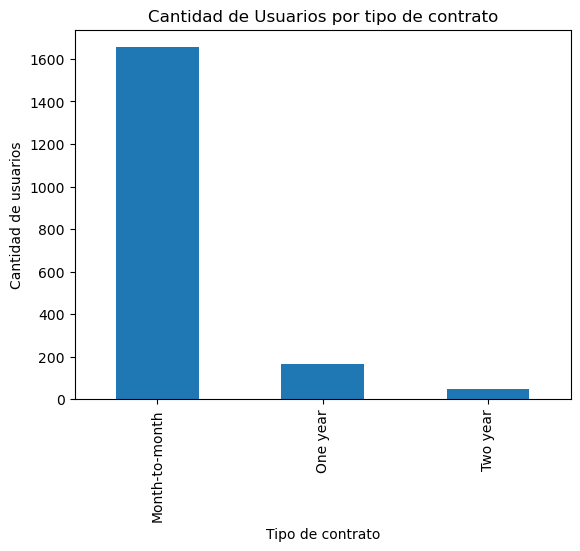

Type
Month-to-month     426.76858
One year          1368.60241
Two year          1864.81250
Name: UserDuration, dtype: float64


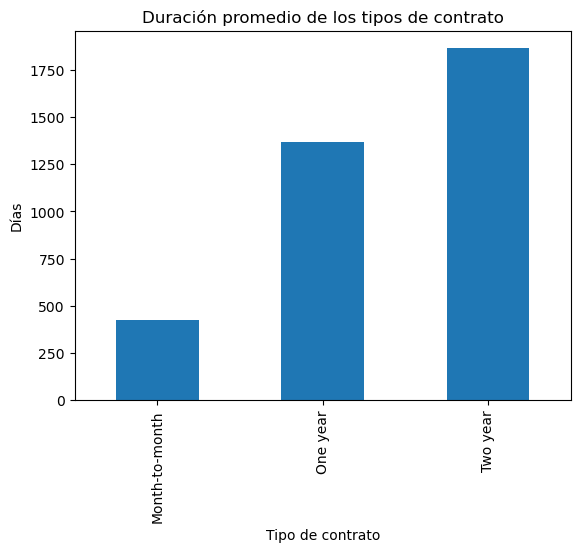

In [14]:
#Grafica de cantidad de usuarios por tipo de contrato
users_type = users_withdrawn.groupby('Type')['customerID'].count()
users_type_plot = users_type.plot( 
    kind = 'bar',
    title = 'Cantidad de Usuarios por tipo de contrato',
    xlabel = 'Tipo de contrato',
    ylabel = 'Cantidad de usuarios')
plt.show(users_type_plot)

#Gráfica de duracion de días por tipo de contrato
users_duration_by_type = users_withdrawn.groupby('Type')['UserDuration'].mean()
print(users_duration_by_type)
users_duration_by_type = users_duration_by_type.plot( 
    kind = 'bar',
    title = 'Duración promedio de los tipos de contrato',
    xlabel = 'Tipo de contrato',
    ylabel = 'Días')
plt.show(users_duration_by_type)

Observaciones: 

Los usuarios que se quedan más tiempo son los que contratan por 2 años y se quedan hasta un promedio de 5.1 años. 

Los usuarios que contratan un año se quedan hasta un promedio de 3.7 años.

Los usuarios que contratan mes con mes se quedan hasta un promedio de 1.2 años.

La cantidad de usuarios es inversamente preoporcional, es decir que la mayoría de clientes contrata la versión mes con mes.

#### Usuarios por tipo de Factura (Papel)

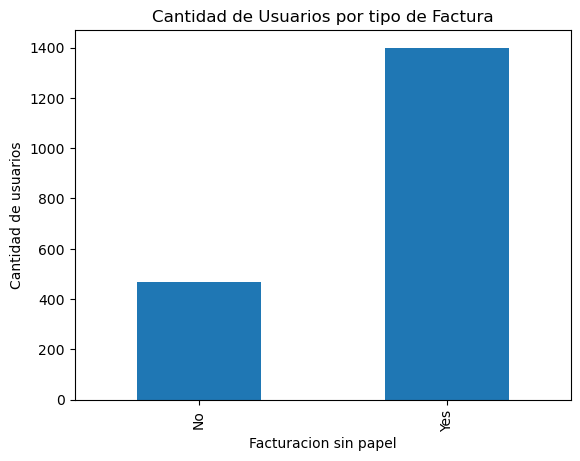

PaperlessBilling
No     475.965885
Yes    571.266429
Name: UserDuration, dtype: float64


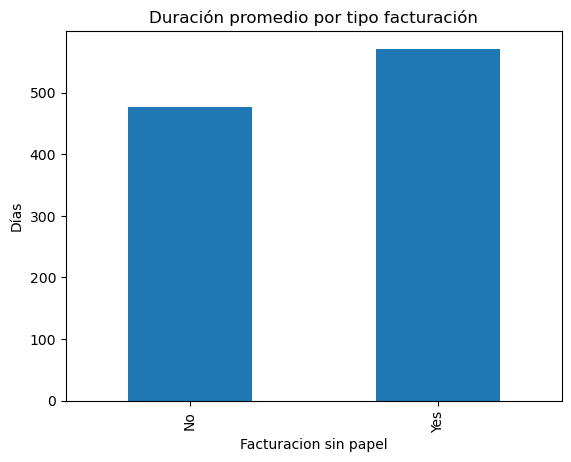

In [15]:
#Gráfica de cantidad de usuarios por tipo de factura
users_bill = users_withdrawn.groupby('PaperlessBilling')['customerID'].count()
users_bill_plot = users_bill.plot( 
    kind = 'bar',
    title = 'Cantidad de Usuarios por tipo de Factura',
    xlabel = 'Facturacion sin papel',
    ylabel = 'Cantidad de usuarios')
plt.show(users_bill_plot)

#Gráfica de duración por tipo de factura
users_duration_by_bill = users_withdrawn.groupby('PaperlessBilling')['UserDuration'].mean()
print(users_duration_by_bill)
users_duration_by_bill = users_duration_by_bill.plot( 
    kind = 'bar',
    title = 'Duración promedio por tipo facturación',
    xlabel = 'Facturacion sin papel',
    ylabel = 'Días')
plt.show(users_duration_by_bill)

Los clientes que piden facturación sin papel son más que los que piden la facturación con papel. 

Facturación sin papel tiene una duración promedio de 1.6 años, mientras que la facturación con papel 1.3 años. 

#### Usuarios por tipo de pago

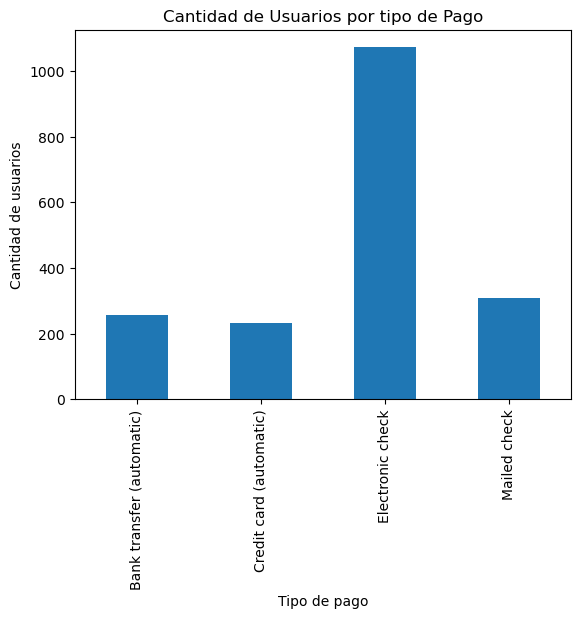

PaymentMethod
Bank transfer (automatic)    800.279070
Credit card (automatic)      837.875000
Electronic check             510.349206
Mailed check                 245.318182
Name: UserDuration, dtype: float64


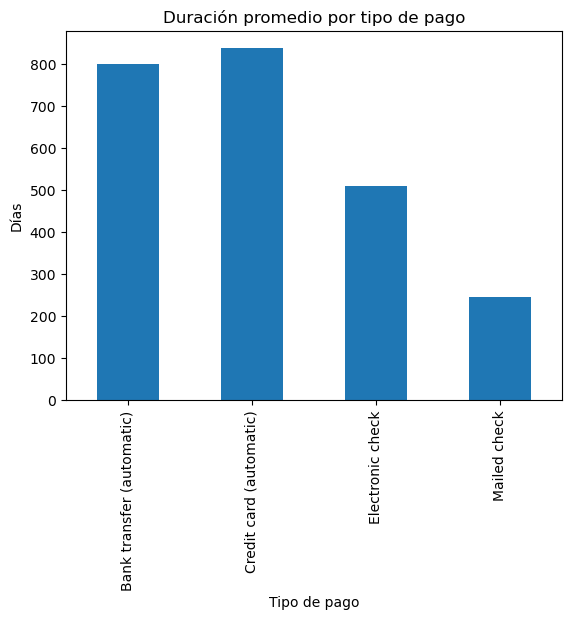

In [16]:
#Gráfica de cantidad de usuarios por tipo de pago
users_pay = users_withdrawn.groupby('PaymentMethod')['customerID'].count()
users_pay_plot = users_pay.plot( 
    kind = 'bar',
    title = 'Cantidad de Usuarios por tipo de Pago',
    xlabel = 'Tipo de pago',
    ylabel = 'Cantidad de usuarios')
plt.show(users_pay_plot)

#Gráfica de duración por tipo de pago
users_duration_by_pay = users_withdrawn.groupby('PaymentMethod')['UserDuration'].mean()
print(users_duration_by_pay)
users_duration_by_pay = users_duration_by_pay.plot( 
    kind = 'bar',
    title = 'Duración promedio por tipo de pago',
    xlabel = 'Tipo de pago',
    ylabel = 'Días')
plt.show(users_duration_by_pay)

Los Usuarios con pago automático suelen quedarse más tiempo (promedio de 2 ños), mientras que los usuarios con pago cheque electrónico duran unos 1.4 años y los que duran menos son los que tienen pago por cheque por correo.

In [17]:
#Género tiene impacto?

### Pre-procesamiento de datos

In [18]:
#Vamos a cambiar los datos de End Date para dividir nuestro DataSet en usuarios que terminaron contrato =1 y los que no =0 
data['End'] = data['EndDate'].apply(
    lambda x: 1 if x == 'No'
    else 0)
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           7043 non-null   object        
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   object        
 8   gender            7043 non-null   object        
 9   SeniorCitizen     7043 non-null   int64         
 10  Partner           7043 non-null   object        
 11  Dependents        7043 non-null   object        
 12  InternetService   7043 non-null   object        
 13  OnlineSecurity    7043 non-null   object        
 14  OnlineBackup      7043 n

## 2.- Entrenamiento de modelos
Se trabajará con modelos de aprendizaje supervizado.

Entrenaré 3 modelos: Regresión lineal, árbol de desición y bosque aleatorio. Se calificará cada uno de ellos y se escogerá el mejor modelo


#### 2.1.- Divisón del dataset


In [19]:
#Dividimos las columnas de Features y Target
features_list_to_drop = ['customerID', 'BeginDate', 'EndDate', 'End']
features = data.drop(features_list_to_drop, axis = 1)
target = data['End']

In [20]:
# Usamos RandomUnderSampler para el balanceo de clases
rus = RandomUnderSampler(random_state=32, sampling_strategy = 'majority')
features_resampled, target_resampled = rus.fit_resample(features, target)
print(features_resampled.shape)
print(target_resampled.shape)

(3738, 17)
(3738,)


In [21]:
#Codificar columnas categóricas a numéricas
encoder = OrdinalEncoder()
features = pd.DataFrame(encoder.fit_transform(features_resampled.to_numpy()), columns = features_resampled.columns )
print(features)

      Type  PaperlessBilling  PaymentMethod  MonthlyCharges  TotalCharges  \
0      0.0               1.0            3.0           338.0          80.0   
1      0.0               1.0            2.0           558.0         484.0   
2      0.0               1.0            2.0          1039.0        3253.0   
3      0.0               1.0            2.0          1130.0        1442.0   
4      0.0               1.0            0.0          1108.0        2296.0   
...    ...               ...            ...             ...           ...   
3733   1.0               0.0            3.0            17.0         345.0   
3734   1.0               0.0            0.0           758.0         891.0   
3735   1.0               0.0            0.0           936.0        2576.0   
3736   0.0               0.0            3.0           237.0        2056.0   
3737   2.0               1.0            0.0           692.0        2534.0   

      gender  SeniorCitizen  Partner  Dependents  InternetService  \
0     

In [22]:
#Dividir en train (60%), test (20%) y valid (20%)
#Vamos a dividir nuestro dataset para entrenar nuestro modelo
train_features, valid_features, train_target, valid_target = train_test_split(features, target_resampled, test_size = 0.4, random_state = 34512)
valid_features, test_features, valid_target, test_target = train_test_split(train_features, train_target, test_size = 0.5, random_state = 34512)
#Revisamos si fue correcta la división de la data
print('Conjunto entrenamiento características:',train_features.shape)
print('Conjunto entrenamiento objetivo:', train_target.shape)
print('Conjunto validación características:',valid_features.shape)
print('Conjunto validación objetivo:',valid_target.shape)
print('Conjunto testeo características:',test_features.shape)
print('Conjunto testeo objetivo:',test_target.shape)

Conjunto entrenamiento características: (2242, 17)
Conjunto entrenamiento objetivo: (2242,)
Conjunto validación características: (1121, 17)
Conjunto validación objetivo: (1121,)
Conjunto testeo características: (1121, 17)
Conjunto testeo objetivo: (1121,)


<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Muy buen trabajo hasta este punto manejando tus datos! Están listos para pasar al desarrollo del modelo
</div>

#### 2.2 Entrenamiento, calificación y ajuste de parámetros de Regresión Lineal
- Se entrenará con el conjunto de train
- Se hará la predicción con el conjunto de valid
- Se calificará con un F1 
- Se visualizará con una matriz de confusión.
- Ajuste de parámetros e hiperparámetros


F1: 0.7258225324027916
              precision    recall  f1-score   support

           0       0.84      0.72      0.78       666
           1       0.66      0.80      0.73       455

    accuracy                           0.75      1121
   macro avg       0.75      0.76      0.75      1121
weighted avg       0.77      0.75      0.76      1121



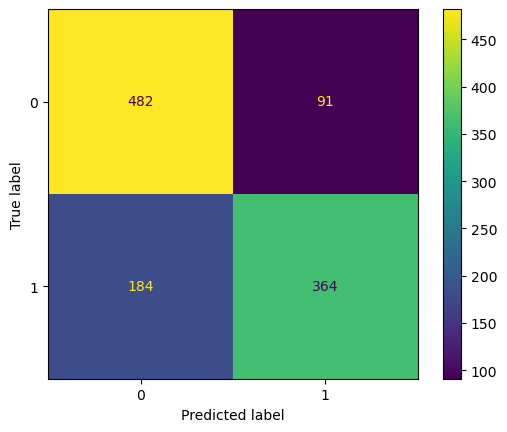

AUC ROC Score Validation 0.8043655494834461


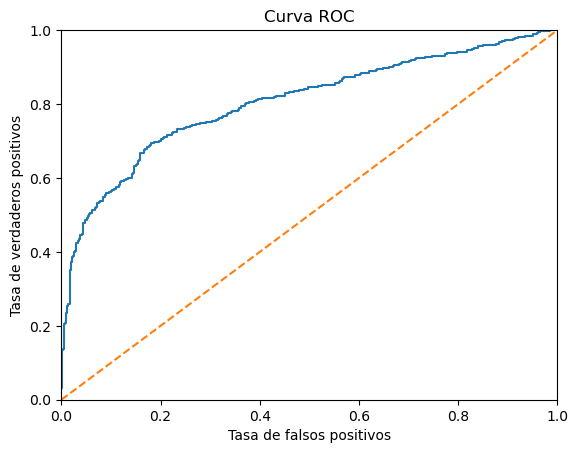

AUC ROC Score Test 0.8235927015292155


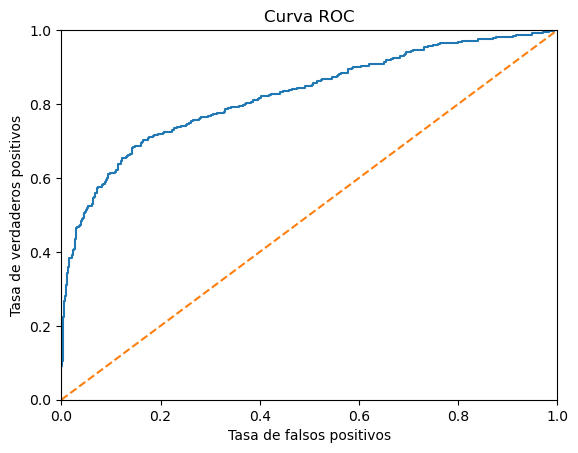

CPU times: total: 1.2 s
Wall time: 540 ms


In [23]:
%%time
#Regresión lineal entrenamiento
model_LR = LogisticRegression(random_state=12345, solver='liblinear', class_weight = 'balanced')
model_LR.fit(train_features, train_target)
predicted_LR = model_LR.predict(valid_features)
#Score
print('F1:', f1_score(valid_target, predicted_LR))
print(
    classification_report(model_LR.predict(valid_features), valid_target)
)

disp= ConfusionMatrixDisplay(confusion_matrix(valid_target, predicted_LR))
disp.plot()
plt.show()

#Calculamos AUC-ROC para el conjunto de validación
p_valid_LR = model_LR.predict_proba(valid_features)[:, 1] 
fpr, tpr, thresholds = roc_curve(valid_target, p_valid_LR )
roc_auc = roc_auc_score(valid_target, p_valid_LR ) 
print('AUC ROC Score Validation' ,roc_auc)

#Graficamos curva ROC para el conjunto de validación
# roc curve for tpr = fpr  
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC')
plt.show()

#Calculamos AUC-ROC para el conjunto de test
p_test_LR = model_LR.predict_proba(test_features)[:, 1] 
fpr, tpr, thresholds = roc_curve(test_target, p_test_LR)
roc_auc = roc_auc_score(test_target, p_test_LR) 
print('AUC ROC Score Test' ,roc_auc)

#Graficamos curva ROC para el conjunto de Test
# roc curve for tpr = fpr  
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC')
plt.show()


Obtenemos un AUC-ROC de 0.80 para el conjunto de entrenamiento y de 0.82 para el de validación, par nuestro modelo de regresión lineal. Es un buen puntaje, sin embargo, vamos a probar otros modelos. 

#### 2.3 Entrenamiento, calificación y ajuste de parámetros de Bosque Aleatorio
- Se entrenará con el conjunto de train
- Se hará la predicción con el conjunto de valid
- Se calificará con un F1 
- Se visualizará con una matriz de confusión.
- Ajuste de parámetros e hiperparámetros

In [24]:
#Elección del mejor n_estimator para Bosque Aleatorio
best_score = 0
best_est = 0
for est in range(1, 20): 
    random_forest = RandomForestClassifier(random_state=54321, n_estimators=est) 
    random_forest.fit(train_features, train_target) 
    score = random_forest.score(valid_features, valid_target) 
    if score > best_score:
        best_score = score
        best_est = est

print("La exactitud del mejor modelo en el conjunto de validación (n_estimators = {}): {}".format(best_est, best_score))

La exactitud del mejor modelo en el conjunto de validación (n_estimators = 19): 0.9964317573595004


F1: 0.9917355371900827
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       580
           1       0.99      1.00      0.99       541

    accuracy                           0.99      1121
   macro avg       0.99      0.99      0.99      1121
weighted avg       0.99      0.99      0.99      1121



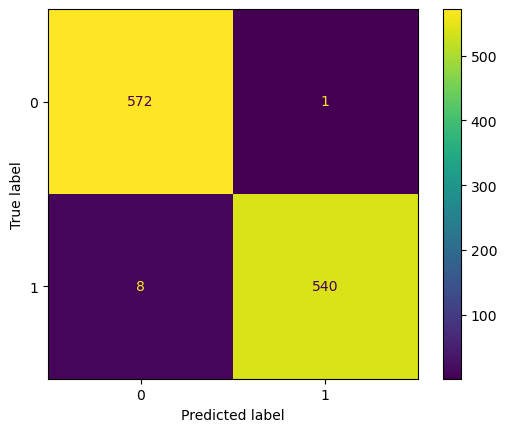

AUC ROC Score Validation 0.9998869441153616


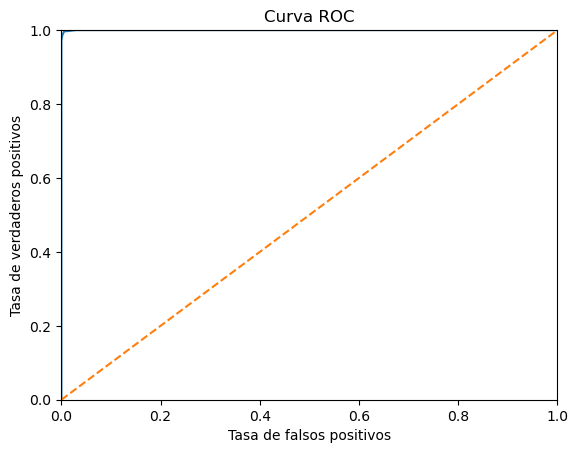

AUC ROC Score Test 0.9998487973821257


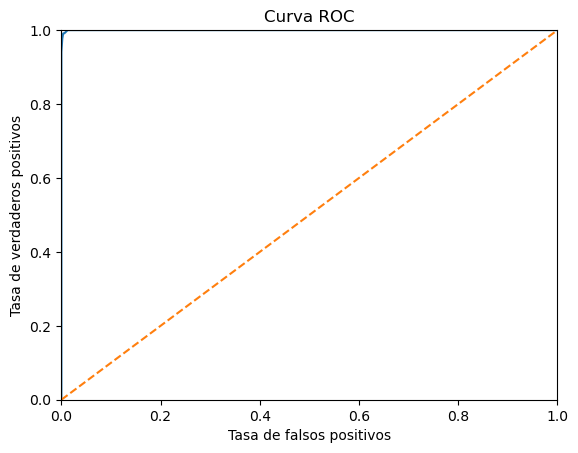

CPU times: total: 359 ms
Wall time: 489 ms


In [25]:
%%time
#Entrenamiento del Random Forest
model_RF = RandomForestClassifier(random_state=12345, n_estimators=19, class_weight = 'balanced')
model_RF.fit(train_features, train_target)
predicted_RF = model_RF.predict(valid_features)
#evaluamos el modelo
print('F1:', f1_score(valid_target, predicted_RF))
print(
    classification_report(model_RF.predict(valid_features), valid_target)
)
disp= ConfusionMatrixDisplay(confusion_matrix(valid_target, predicted_RF))
disp.plot()
plt.show()
#Calculamos AUC-ROC para el conjunto de validación
p_valid_RF = model_RF.predict_proba(valid_features)[:, 1] 
fpr, tpr, thresholds = roc_curve(valid_target, p_valid_RF)
roc_auc = roc_auc_score(valid_target, p_valid_RF) 
print('AUC ROC Score Validation' ,roc_auc)

#Graficamos curva ROC para el conjunto de validación
# roc curve for tpr = fpr  
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC')
plt.show()

#Calculamos AUC-ROC para el conjunto de test
p_test_RF = model_RF.predict_proba(test_features)[:, 1] 
fpr, tpr, thresholds = roc_curve(test_target, p_test_RF)
roc_auc = roc_auc_score(test_target, p_test_RF) 
print('AUC ROC Score Test' ,roc_auc)

#Graficamos curva ROC test
# roc curve for tpr = fpr  
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC')
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Buen trabajo con los entrenamientos! Obtuviste modelos bastante robustos que logran realizar las predicciones adecuadas para tu variable objetivo.
</div>

### 4.- Conclusiones y discusión

Si bien el modelo de Random Forest tuvo un mejor performance, me gustaría saber qué puedo hacer adicional a esto. 
Creo que algo que no vimos en el bootcamp fue cómo poner en práctica nuestro modelo...por ejemplo, en este caso ¿cómo puedo visualizar una predicción para un usuario en específico? (ya sea en una tabla, gráfica, etc), ésto con la finalidad de realizar la aportación a detectar los usuarios que se podrían ir y poner en práctica las ofertas.

Espero comentarios y gracias por la revisión :)

<div class="alert alert-block alert-success">
<b>Comentario general (1ra Iteracion)</b> <a class=“tocSkip”></a>

¡Muy buen trabajo Laura! Se nota los conocimientos adquiridos en tu formación cómo Data Scientist, manejaste muy bien los análisis y presentaste métricas correctas en tus modelos. Cuando tengas modelos con desempeño similar puedes escoger cómo lo has hecho aquí o puedes calcular el tiempo que tardan en realizar un predicción y escoger el que sea más rápido para que cuando sea expuesto para ser usado la respuesta sea en poco tiempo.
    
Me gustaría dejarte algunas recomendaciones para que resaltes tu perfil profesional en el mundo laboral:
    
- **Exponer los modelos:** Puedes agregar más valor a tu perfil profesional exponiendo los modelos para que puedan ser utilizados en algún demo, esto puedes hacerlo con streamlit y en render.com cómo lo hiciste en un sprint anterior. Pero si quieres ir más allá también podrías investigar y hacerlo utilizando el framework de FastAPI.
- **Herramientas cloud:** Para demostrar un perfil más completo, también podrías utilizar algún servicio cloud cómo AWS y tratar de subir tus modelos entrenados ahí. No tienes que hacerlo a manera de experto, pero siempre es un plus tener conocimiento de estas herramientas.
- **Continúa aprendiendo y practicando:** La práctica hace al maestro, mientras más practiques más errores podrás solucionar y estarás más listo para afrontar problemas reales en un entorno laboral.
    
Saludos y felicidades!
</div>

# CONCLUSIONES

¿Qué pasos del plan se realizaron y qué pasos se omitieron (explica por qué)?

La mayoría de los pasos se realizaron, excepto que no hubo necesidad de tratar duplicados, y tampoco de utilizar descenso de gradiente ya que los modelos que se utilizaron fueron bastante buenos por sí mismos, sin verse sobreajustados o subajustados.  


¿Qué dificultades encontraste y cómo lograste resolverlas?

Durante la realización de este proyecto, me enfrenté con el problema del balanceo de clases, ya que, aunque lo vimos en el bootcamp, no tuvimos un proyecto que involucrara el balanceo de clases. Me salían algunos errores, puesto que tenía que instalar algunas cosas desde anaconda (que fue el programa que utilicé durante lo largo del bootcamp), simplemente googleé cómo resolver este problema y di solución. 

¿Cuáles fueron algunos de los pasos clave para resolver la tarea?

No sabía como abordar el tema de las clases. Primero pensé en una serie temporal para uno de los grupos y después al poder colaborar con otros compañeros me di cuenta que sería más fácil asignar 0 a los usuarios que no habían concluído contrato y 1 a quienes ya habían concluído contrato. 

¿Cuál es tu modelo final y qué nivel de calidad tiene?

Finalmente, podemos observar que el modelo de bosque aleatorio fue más rápido, y con mejor puntuación AUC-ROC, por lo que convendría tomarlo como modelo final. 

<div class="alert alert-block alert-success">
<b>Comentario general para Informe de Solución (1ra Iteracion)</b> <a class=“tocSkip”></a>

¡Felicidades Laura! Completaste tu proyecto con un informe bastante detallado de los resultados obtenidos y los pasos realizados para llegar hasta ellos. 
    
La redacción de tus pasos y procesos es muy clara, redactaste muy bien los resultados de tu modelo y las métricas utilizadas dejando claro que el entrenamiento y evaluación salieron de manera correcta.
    
Sin más, sólo me queda decir que la práctica hace al maestro, te invito a seguir profundizando en más tecnicas de machine learning y también a como llevar estos modelos a un entorno productivo donde pueda dar más valor a la empresa para la cual se lo plantee.

Saludos!
</div>